# Module 1: Data Exploration, Wrangling, and Cleaning 
### ● Inspection & Null Imputation
### ● Outlier Detection

In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Customer-Churn-Prediction.csv")

# Basic inspection
print("Shape of dataset:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Shape of dataset: (7043, 21)

First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport Stre

In [2]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing values after TotalCharges conversion:")
print(df.isnull().sum())

Missing values after TotalCharges conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [3]:
# Identify numerical columns
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()

# Identify categorical columns
categorical_cols = df.select_dtypes(
    include=['object', 'string']
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [4]:
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [5]:
def detect_outliers_iqr(data, columns):
    outlier_summary = []

    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[
            (data[col] < lower_bound) |
            (data[col] > upper_bound)
        ]

        outlier_summary.append({
            "Column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": len(outliers)
        })

    return pd.DataFrame(outlier_summary)

In [6]:
outlier_results = detect_outliers_iqr(
    df,
    numerical_cols
)

print(outlier_results)

           Column       Q1       Q3       IQR  Lower Bound  Upper Bound  \
0   SeniorCitizen    0.000     0.00     0.000       0.0000       0.0000   
1          tenure    9.000    55.00    46.000     -60.0000     124.0000   
2  MonthlyCharges   35.500    89.85    54.350     -46.0250     171.3750   
3    TotalCharges  402.225  3786.60  3384.375   -4674.3375    8863.1625   

   Outlier Count  
0           1143  
1              0  
2              0  
3              0  


In [7]:
iqr_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

outlier_results = detect_outliers_iqr(
    df,
    iqr_cols
)

print(outlier_results)

           Column       Q1       Q3       IQR  Lower Bound  Upper Bound  \
0          tenure    9.000    55.00    46.000     -60.0000     124.0000   
1  MonthlyCharges   35.500    89.85    54.350     -46.0250     171.3750   
2    TotalCharges  402.225  3786.60  3384.375   -4674.3375    8863.1625   

   Outlier Count  
0              0  
1              0  
2              0  


In [8]:
for col in iqr_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    print(f"\nColumn: {col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Outliers: {outlier_count}")


Column: tenure
Q1: 9.00
Q3: 55.00
IQR: 46.00
Lower Bound: -60.00
Upper Bound: 124.00
Outliers: 0

Column: MonthlyCharges
Q1: 35.50
Q3: 89.85
IQR: 54.35
Lower Bound: -46.02
Upper Bound: 171.38
Outliers: 0

Column: TotalCharges
Q1: 402.23
Q3: 3786.60
IQR: 3384.38
Lower Bound: -4674.34
Upper Bound: 8863.16
Outliers: 0


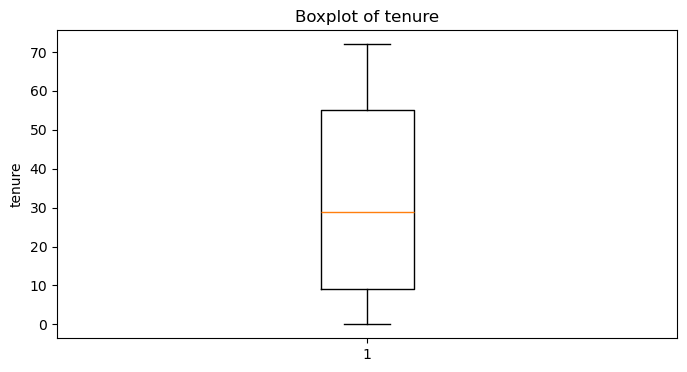

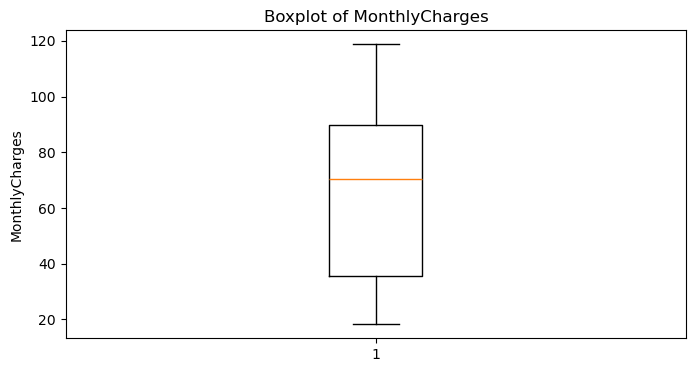

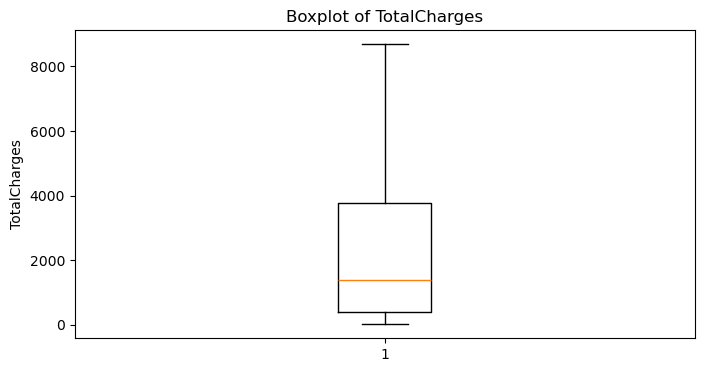

In [9]:
import matplotlib.pyplot as plt

for col in iqr_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna())
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.show()

In [10]:
df.to_csv(
    "Customer-Churn-Prediction-Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


# Module 2: Feature Engineering, Encoding, and Scaling 
### ● Categorical Encoding
### ● Feature Engineering
### ● Feature Scaling

In [11]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("ecommerce_customer_behavior_2026.csv")

print("Shape:", df.shape)
print(df.head())

Shape: (100000, 50)
   Customer_ID   Customer_Name  Customer_Age  Gender    Country  \
0  CUST-000001      Mateo Park            65    Male     Canada   
1  CUST-000002     James Brown            45    Male    Belgium   
2  CUST-000003  Sophia Mendoza            20  Female  Argentina   
3  CUST-000004   Carlos Wilson            74  Female      Kenya   
4  CUST-000005    Grace Garcia            42  Female  Indonesia   

       Continent      City         Region  Customer_Segment  \
0  North America  Edmonton         Quebec      New Customer   
1         Europe   Antwerp  East Flanders  Dormant Customer   
2  South America   Mendoza       Santa Fe  Regular Customer   
3         Africa   Mombasa    Uasin Gishu      New Customer   
4           Asia   Jakarta      West Java      New Customer   

  Account_Creation_Date  ... Loyalty_Points  Loyalty_Tier  \
0            2024-02-22  ...              0        Bronze   
1            2024-06-04  ...              0        Bronze   
2            20

In [12]:
# Calculate total engagement time in hours
df["Total_Engagement_Hours"] = (
    df["Total_Sessions"] *
    df["Average_Session_Duration_Minutes"] / 60
)

# Engagement Efficiency Index
# +1 avoids division by zero for customers with $0 spending
df["Engagement_Efficiency_Index"] = (
    df["Total_Engagement_Hours"] /
    (df["Total_Spending_USD"] + 1)
)

print(df[
    [
        "Total_Sessions",
        "Average_Session_Duration_Minutes",
        "Total_Spending_USD",
        "Total_Engagement_Hours",
        "Engagement_Efficiency_Index"
    ]
].head())

   Total_Sessions  Average_Session_Duration_Minutes  Total_Spending_USD  \
0               9                              25.6                0.00   
1               5                              21.0                0.00   
2              28                              10.2              130.15   
3              17                              33.9                0.00   
4               2                              45.2                0.00   

   Total_Engagement_Hours  Engagement_Efficiency_Index  
0                3.840000                     3.840000  
1                1.750000                     1.750000  
2                4.760000                     0.036294  
3                9.605000                     9.605000  
4                1.506667                     1.506667  


In [13]:
df = pd.get_dummies(
    df,
    columns=["Preferred_Device"],
    prefix="Preferred_Device",
    dtype=int
)

print(df.columns.tolist())

['Customer_ID', 'Customer_Name', 'Customer_Age', 'Gender', 'Country', 'Continent', 'City', 'Region', 'Customer_Segment', 'Account_Creation_Date', 'Last_Activity_Date', 'Total_Sessions', 'Total_Page_Views', 'Average_Session_Duration_Minutes', 'Products_Viewed', 'Products_Added_To_Cart', 'Cart_Abandonment_Count', 'Total_Orders', 'Completed_Orders', 'Cancelled_Orders', 'Returned_Orders', 'Total_Items_Purchased', 'Total_Spending_USD', 'Average_Order_Value_USD', 'Discount_Usage_Count', 'Average_Discount_Percentage', 'Coupon_Usage_Count', 'Wishlist_Items', 'Product_Reviews_Count', 'Average_Product_Rating', 'Customer_Support_Contacts', 'Complaint_Count', 'Preferred_Category', 'Preferred_Payment_Method', 'Preferred_Marketing_Channel', 'Email_Open_Rate_Percentage', 'Email_Click_Rate_Percentage', 'Push_Notification_Engagement_Percentage', 'Social_Media_Engagement_Score', 'Loyalty_Points', 'Loyalty_Tier', 'Customer_Lifetime_Value_USD', 'Churn_Risk_Score', 'Churn_Risk_Level', 'Purchase_Frequency',

In [14]:
categorical_columns = ["Subscription_Type", "Preferred_Device"]

existing_columns = [
    col for col in categorical_columns
    if col in df.columns
]

df = pd.get_dummies(
    df,
    columns=existing_columns,
    dtype=int
)

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Don't scale identifiers
exclude_columns = [
    "Customer_ID"
]

scale_columns = [
    col for col in numeric_columns
    if col not in exclude_columns
]

df[scale_columns] = scaler.fit_transform(
    df[scale_columns]
)

print(df[scale_columns].head())

   Customer_Age  Total_Sessions  Total_Page_Views  \
0      1.103022       -0.588092         -0.737627   
1     -0.092748       -0.753102         -0.737627   
2     -1.587461        0.195703          0.688796   
3      1.641119       -0.258073         -0.455993   
4     -0.272114       -0.876859         -0.776743   

   Average_Session_Duration_Minutes  Products_Viewed  Products_Added_To_Cart  \
0                         -0.190750        -0.748410               -0.686404   
1                         -0.447485        -0.710664               -0.686404   
2                         -1.050252         0.374519                0.593266   
3                          0.272488        -0.521937               -0.449428   
4                          0.903161        -0.672919               -0.639009   

   Cart_Abandonment_Count  Total_Orders  Completed_Orders  Cancelled_Orders  \
0               -0.566549      -0.61665         -0.465123         -0.815584   
1               -0.566549      -0.61665   

In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# ==========================================
# STEP 1: LOAD DATA
# ==========================================

df = pd.read_csv("ecommerce_customer_behavior_2026.csv")

print("Original Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# ==========================================
# STEP 2: FEATURE ENGINEERING
# ==========================================

# Total engagement time in hours
df["Total_Engagement_Hours"] = (
    df["Total_Sessions"] *
    df["Average_Session_Duration_Minutes"] / 60
)

# Engagement Efficiency Index
df["Engagement_Efficiency_Index"] = (
    df["Total_Engagement_Hours"] /
    (df["Total_Spending_USD"] + 1)
)

print("\nEngineered Features:")
print(
    df[
        [
            "Total_Engagement_Hours",
            "Engagement_Efficiency_Index"
        ]
    ].head()
)


# ==========================================
# STEP 3: CATEGORICAL ENCODING
# ==========================================

# Encode available categorical variables
categorical_columns = [
    "Subscription_Type",
    "Preferred_Device"
]

# Only use columns actually present in dataset
existing_columns = [
    col for col in categorical_columns
    if col in df.columns
]

print("\nCategorical columns available:", existing_columns)

df = pd.get_dummies(
    df,
    columns=existing_columns,
    dtype=int
)

print("\nEncoding completed.")


# ==========================================
# STEP 4: FEATURE SCALING
# ==========================================

scaler = StandardScaler()

# Select numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Exclude ID columns
exclude_columns = [
    "Customer_ID"
]

scale_columns = [
    col for col in numeric_columns
    if col not in exclude_columns
]

# Standardization
df[scale_columns] = scaler.fit_transform(
    df[scale_columns]
)

print("\nScaling completed.")


# ==========================================
# STEP 5: VERIFY
# ==========================================

print("\nFinal Shape:", df.shape)

print("\nFinal Dataset:")
print(df.head())

print("\nMean after scaling:")
print(df[scale_columns].mean().head())

print("\nStandard deviation after scaling:")
print(df[scale_columns].std().head())


# ==========================================
# STEP 6: SAVE PROCESSED DATA
# ==========================================

df.to_csv(
    "ecommerce_customer_behavior_2026_module2_processed.csv",
    index=False
)

print("\nModule 2 processing completed successfully!")

Original Shape: (100000, 50)

Columns:
['Customer_ID', 'Customer_Name', 'Customer_Age', 'Gender', 'Country', 'Continent', 'City', 'Region', 'Customer_Segment', 'Account_Creation_Date', 'Last_Activity_Date', 'Total_Sessions', 'Total_Page_Views', 'Average_Session_Duration_Minutes', 'Products_Viewed', 'Products_Added_To_Cart', 'Cart_Abandonment_Count', 'Total_Orders', 'Completed_Orders', 'Cancelled_Orders', 'Returned_Orders', 'Total_Items_Purchased', 'Total_Spending_USD', 'Average_Order_Value_USD', 'Discount_Usage_Count', 'Average_Discount_Percentage', 'Coupon_Usage_Count', 'Wishlist_Items', 'Product_Reviews_Count', 'Average_Product_Rating', 'Customer_Support_Contacts', 'Complaint_Count', 'Preferred_Category', 'Preferred_Payment_Method', 'Preferred_Device', 'Preferred_Marketing_Channel', 'Email_Open_Rate_Percentage', 'Email_Click_Rate_Percentage', 'Push_Notification_Engagement_Percentage', 'Social_Media_Engagement_Score', 'Loyalty_Points', 'Loyalty_Tier', 'Customer_Lifetime_Value_USD', 'C

# Module 3: Feature Selection and Validation Setup 
### ● Feature Selection
### ● Validation Strategy

In [17]:
# ============================================================
# MODULE 3: FEATURE SELECTION AND VALIDATION STRATEGY
# Customer Churn Prediction
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv("Customer-Churn-Prediction.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. DATA PREPARATION
# ------------------------------------------------------------

# Convert TotalCharges from object to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Convert target variable to numerical format
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Remove customer ID because it is not a predictive variable
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Distribution (%):")
print(y.value_counts(normalize=True) * 100)


# ------------------------------------------------------------
# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object', 'string']
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))


# ------------------------------------------------------------
# 4. PREPROCESSING
# ------------------------------------------------------------

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])


# ------------------------------------------------------------
# 5. TRANSFORM FEATURES
# ------------------------------------------------------------

X_processed = preprocessor.fit_transform(X)

feature_names = preprocessor.get_feature_names_out()

X_processed = pd.DataFrame(
    X_processed,
    columns=feature_names,
    index=X.index
)

print("\nProcessed Feature Shape:")
print(X_processed.shape)


# ------------------------------------------------------------
# 6. RECURSIVE FEATURE ELIMINATION (RFE)
# ------------------------------------------------------------

logistic_model = LogisticRegression(
    max_iter=2000,
    solver="liblinear"
)

# Select the 15 most important encoded features
rfe = RFE(
    estimator=logistic_model,
    n_features_to_select=15,
    step=0.1
)

rfe.fit(X_processed, y)


# ------------------------------------------------------------
# 7. DISPLAY SELECTED FEATURES
# ------------------------------------------------------------

selected_features = feature_names[rfe.support_]

print("\n========================================")
print("SELECTED FEATURES USING RFE")
print("========================================")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")


# ------------------------------------------------------------
# 8. FEATURE RANKING
# ------------------------------------------------------------

feature_ranking = pd.DataFrame({
    "Feature": feature_names,
    "RFE_Rank": rfe.ranking_,
    "Selected": rfe.support_
})

feature_ranking = feature_ranking.sort_values(
    by="RFE_Rank"
)

print("\n========================================")
print("RFE FEATURE RANKING")
print("========================================")

print(feature_ranking.to_string(index=False))


# ------------------------------------------------------------
# 9. CREATE REDUCED DATASET
# ------------------------------------------------------------

X_selected = X_processed.loc[:, rfe.support_]

print("\nReduced Dataset Shape:")
print(X_selected.shape)


# ------------------------------------------------------------
# 10. STRATIFIED K-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    logistic_model,
    X_selected,
    y,
    cv=skf,
    scoring="accuracy"
)


# ------------------------------------------------------------
# 11. CROSS-VALIDATION RESULTS
# ------------------------------------------------------------

print("\n========================================")
print("STRATIFIED K-FOLD RESULTS")
print("========================================")

for fold, score in enumerate(cv_scores, start=1):
    print(f"Fold {fold}: {score:.4f}")

print("\nMean Accuracy:",
      round(cv_scores.mean(), 4))

print("Standard Deviation:",
      round(cv_scores.std(), 4))

Dataset Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target Distribution (%):
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64
Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Processed Feature Shape:
(7043, 45)

SELECTED FEATURES USING RFE
1. num__tenure
2. num__MonthlyCharges
3. num__TotalCharges
4

# Module 4: Model Tuning and Baseline Algorithms 
### ● Hyperparameter Search 
### ● Baseline Modeling

In [4]:
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from scipy.stats import randint, loguniform

In [5]:
# Load dataset
df = pd.read_csv("Customer-Churn-Prediction.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [6]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove customer ID
df = df.drop(columns=["customerID"])

# Convert target variable
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [7]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nChurn distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True))

Features: (7043, 19)
Target: (7043,)

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [8]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


In [11]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

In [12]:
rf_parameters = {
    "classifier__n_estimators": randint(100, 301),

    "classifier__max_depth": [
        None,
        5,
        8,
        10,
        15,
        20,
        25
    ],

    "classifier__min_samples_split": randint(2, 10),

    "classifier__min_samples_leaf": randint(1, 6),

    "classifier__max_features": [
        "sqrt",
        "log2"
    ]
}

In [13]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [14]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_parameters,
    n_iter=8,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_random_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'classifier__max_depth': [None, 5, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': <scipy.stats....00285215196D0>, 'classifier__min_samples_split': <scipy.stats....002852144B610>, ...}"
,n_iter,8
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [15]:
print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

print("\nBest CV F1 Score:")
print(rf_random_search.best_score_)

Best Random Forest Parameters:
{'classifier__max_depth': 8, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 3, 'classifier__n_estimators': 187}

Best CV F1 Score:
0.6335247179897829


In [16]:
ada_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        random_state=42
    ))
])

In [17]:
ada_parameters = {
    "classifier__n_estimators": randint(50, 251),

    "classifier__learning_rate": loguniform(
        0.03,
        1.0
    )
}

In [18]:
ada_random_search = RandomizedSearchCV(
    estimator=ada_pipeline,
    param_distributions=ada_parameters,
    n_iter=6,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

ada_random_search.fit(X_train, y_train)
print("Best AdaBoost Parameters:")
print(ada_random_search.best_params_)

print("\nBest AdaBoost CV F1:")
print(ada_random_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best AdaBoost Parameters:
{'classifier__learning_rate': np.float64(0.24691446306928397), 'classifier__n_estimators': 201}

Best AdaBoost CV F1:
0.5742294562173758


In [19]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

In [20]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=15,
        weights="distance"
    ))
])

In [21]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

In [22]:
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Tuned Random Forest": rf_random_search.best_estimator_,
    "Tuned AdaBoost": ada_random_search.best_estimator_
}

In [23]:
scoring_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV F1",
    ascending=False
)

results_df.round(4)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
3,Tuned Random Forest,0.7625,0.5366,0.7739,0.6335,0.8466
0,Logistic Regression,0.7490,0.5176,0.8013,0.6288,0.8459
2,SVM,0.7501,0.5192,0.7819,0.6239,0.8269
4,Tuned AdaBoost,0.8032,0.6752,0.5010,0.5742,0.8489
1,KNN,0.7730,0.5784,0.5351,0.5558,0.8049


In [24]:
test_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
    else:
        probabilities = model.decision_function(X_test)

    test_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Test Precision": precision_score(
            y_test,
            predictions
        ),
        "Test Recall": recall_score(
            y_test,
            predictions
        ),
        "Test F1": f1_score(
            y_test,
            predictions
        ),
        "Test ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    })

test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="Test F1",
    ascending=False
)

test_results_df.round(4)

,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
3,Tuned Random Forest,0.7573,0.5288,0.7861,0.6323,0.8439
2,SVM,0.7438,0.5115,0.7727,0.6155,0.8213
0,Logistic Regression,0.7374,0.5034,0.7834,0.6130,0.8415
4,Tuned AdaBoost,0.7991,0.6585,0.5053,0.5719,0.8426
1,KNN,0.7651,0.5599,0.5374,0.5484,0.8020


In [25]:
final_comparison = results_df.merge(
    test_results_df,
    on="Model"
)

final_comparison.round(4)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Tuned Random Forest,0.7625,0.5366,0.7739,0.6335,0.8466,0.7573,0.5288,0.7861,0.6323,0.8439
1,Logistic Regression,0.7490,0.5176,0.8013,0.6288,0.8459,0.7374,0.5034,0.7834,0.6130,0.8415
2,SVM,0.7501,0.5192,0.7819,0.6239,0.8269,0.7438,0.5115,0.7727,0.6155,0.8213
3,Tuned AdaBoost,0.8032,0.6752,0.5010,0.5742,0.8489,0.7991,0.6585,0.5053,0.5719,0.8426
4,KNN,0.7730,0.5784,0.5351,0.5558,0.8049,0.7651,0.5599,0.5374,0.5484,0.8020


# Module 5: Ensemble Learning and Final Evaluation 
### ● Ensemble Architectures: Implement bagging (Random Forest) and boosting (AdaBoost) models. 
### ● Model Comparison: Compare cross-validation metrics across all models to provide stakeholders with an actionable deployment recommendation. 

In [1]:
# ============================================================
# MODULE 5: ENSEMBLE LEARNING AND FINAL EVALUATION
# Customer Churn Prediction
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

import warnings
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv("Customer-Churn-Prediction.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. DATA PREPARATION
# ------------------------------------------------------------

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove customer identifier
X = df.drop(columns=["Churn", "customerID"])

# Convert target into 0/1
y = (
    df["Churn"]
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)


# ------------------------------------------------------------
# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# ------------------------------------------------------------
# 4. PREPROCESSING
# ------------------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


# ------------------------------------------------------------
# 5. DEFINE MODELS
# ------------------------------------------------------------

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    # BAGGING
    "Random Forest (Bagging)": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    # BOOSTING
    "AdaBoost (Boosting)": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    )
}


# ------------------------------------------------------------
# 6. STRATIFIED 5-FOLD CROSS VALIDATION
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


# ------------------------------------------------------------
# 7. MODEL EVALUATION
# ------------------------------------------------------------

results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })


# ------------------------------------------------------------
# 8. CREATE COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("\n========================================")
print("FINAL MODEL COMPARISON")
print("========================================")

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    "customer_churn_model_comparison.csv",
    index=False
)

print("\nResults saved as:")
print("customer_churn_model_comparison.csv")

Dataset Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

FINAL MODEL COMPARISON
                  Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
    Logistic Regression    0.7456     0.5132  0.8015    0.6257   0.8449
                    SVM    0.7518     0.5219  0.7753    0.6238   0.8259
          Decision Tree    0.7295     0.4942  0.8084  